# IT9002 Natural Language Processing — Individual Project
## Notebook 3 of 3: Task 1 by prompting two local LLMs (zero-shot and few-shot)

**Dataset.** CUAD v1 — Contract Understanding Atticus Dataset (Hendrycks, Burns, Chen & Ball, 2021; CC BY 4.0).
Official page: https://www.atticusprojectai.org/cuad · data and code: https://github.com/TheAtticusProject/cuad

**Question.** Can a small instruction-tuned language model, with no training at all, classify contract clauses into our 27
categories — and how does it compare with the fine-tuned Legal-BERT of notebook 1 on macro-F1, cost and latency?

**Models (both run locally on the GPU with the `transformers` library, bf16, each with its own chat template):**
- primary — `Qwen/Qwen2.5-1.5B-Instruct` (Apache-2.0);
- second — `Qwen/Qwen2.5-3B-Instruct` (Qwen Research Licence). The planned second model, `meta-llama/Llama-3.2-3B-Instruct`,
  is gated and was not accessible from this machine; the fallback is deviation **D3** in the report.

**Important framing.** These are *small open* models (1.5 B and 3 B parameters) used without any training. Their scores are
a **lower bound for what prompting can do**, not a statement about large hosted LLMs.

**Protocol (test set stays clean).** Three prompt versions per model are run on the full **validation** set; the version
with the best validation macro-F1 is chosen per model and run **once** on the 1,444 test clauses through the test-once
helper (`results/test_eval_log.csv`). Decoding is greedy (deterministic).

### How to run
- Top to bottom. The long generation runs are done by `scripts/run_llm.py` and saved in `results/llm/`; with
  `RERUN = False` (default) the notebook parses the saved raw outputs, so it re-runs in a few minutes. The test outputs and
  latency measurements are produced by the same script on the first run (or when missing).
- Google Colab: set the GitHub URL in the first cell; a GPU runtime is needed for the model cells.

## ▶ Run on Google Colab (skip this on your own computer)
**For markers using Google Colab.** Runtime → Change runtime type → **GPU** (T4 is enough), then Runtime → **Run all**.
The cell below gets the project — from the GitHub repository if its URL is set, otherwise from the submission ZIP uploaded
to Google Drive (default `MyDrive/IT9002_202609212.zip`; change `ZIP_PATH` if it is elsewhere) — installs the pinned
packages and moves into the project folder. On your own computer it does nothing. Colab starts without the trained models
(`models/`, too large to share), so cells that need them print **SKIPPED** with retraining instructions and then show the
outputs those cells produced in the real run (tables, figures, text, labelled SAVED); the DEMO sections do the same.

In [1]:
# ==== RUN ON GOOGLE COLAB - does nothing on your own computer ====
import os, sys, subprocess, zipfile
from pathlib import Path
SIMULATE = os.environ.get("IT9002_SIMULATE_COLAB") == "1"         # local test of the Colab path
IN_COLAB = "google.colab" in sys.modules or SIMULATE
GITHUB_URL = "https://github.com/202609212-AbdullaAlhermi/IT9002-202609212-Project"                             # the project's GitHub repository (as in project_info.json)
ZIP_PATH = "/content/drive/MyDrive/IT9002_202609212.zip"           # used when the repository cannot be cloned

def find_root(start):
    """The project folder = the first folder, going upwards, that contains project_info.json."""
    return next((d for d in [start, *start.parents] if (d / "project_info.json").exists()), None)

if IN_COLAB:
    base = Path(os.environ.get("IT9002_COLAB_BASE", "/content"))
    root = find_root(Path.cwd())
    if root is None and GITHUB_URL.startswith("https://github.com/"):            # a) clone the repository
        clone = base / "IT9002_project"
        if not clone.exists():
            # no password prompt: a private repository simply fails here and the ZIP route below is used instead
            r = subprocess.run(["git", "-c", "credential.helper=", "clone", "--depth", "1", GITHUB_URL, str(clone)],
                               env=dict(os.environ, GIT_TERMINAL_PROMPT="0"), capture_output=True, text=True)
            if r.returncode != 0:
                print("Could not clone the repository (it may be private); using the submission ZIP from Google Drive.")
        root = clone if (clone / "project_info.json").exists() else None
    if root is None:                                                             # b) unzip the submission ZIP from Drive
        if not SIMULATE:
            from google.colab import drive
            drive.mount("/content/drive")
        zp = Path(os.environ.get("IT9002_COLAB_ZIP", ZIP_PATH))
        assert zp.exists(), f"Upload the submission ZIP to Google Drive and set ZIP_PATH (not found: {zp})"
        with zipfile.ZipFile(zp) as z:
            root = base / z.namelist()[0].split("/")[0]
            if not root.exists():
                z.extractall(base)
    os.chdir(root / "notebooks")
    # pinned requirements, but keep Colab's own CUDA build of torch and its Jupyter packages
    keep = ("torch", "jupyterlab", "ipykernel", "nbformat", "nbconvert", "nbclient")
    reqs = [l.strip() for l in (root / "requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith("#") and not l.split("==")[0].strip().lower().startswith(keep)]
    (root / "requirements_colab.txt").write_text("\n".join(reqs) + "\n")
    loaded = {m: sys.modules[m].__version__ for m in ("numpy", "pandas", "scipy", "sklearn") if m in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements_colab.txt")]
                   + (["--dry-run"] if SIMULATE else []), check=True)
    pins = dict(l.split("==") for l in reqs if "==" in l)
    stale = [m for m, v in loaded.items() if pins.get({"sklearn": "scikit-learn"}.get(m, m), v) != v]
    if stale and not SIMULATE:
        raise RuntimeError(f"New versions of {stale} were installed: Runtime -> Restart session, then Run all again.")
    from importlib.metadata import version
    print(f"Colab: project folder {root} | pinned requirements {'checked (dry run)' if SIMULATE else 'installed'} | "
          f"torch {version('torch')} kept")
else:
    print("Not on Colab: nothing to do here.")

Not on Colab: nothing to do here.


## 0. Setup

In [2]:
import sys, os, json, platform, subprocess, importlib, time, warnings, inspect
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules or os.environ.get("IT9002_SIMULATE_COLAB") == "1"
# The project folder = the first folder, going upwards, that contains project_info.json (works from notebooks/, from the
# project folder and on Colab, where the cell above has moved into the project).
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "project_info.json").exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", message="IProgress not found")

from src import common as C, llm as L, plotting as PL
for mod in (C, L, PL):
    importlib.reload(mod)
import numpy as np, pandas as pd, torch, transformers, sklearn
import matplotlib.pyplot as plt
transformers.logging.set_verbosity_error()
C.set_seed(42); PL.setup_style()
INFO = C.load_project_info()
print(f"Student: {INFO['STUDENT_NAME']} | ID: {INFO['STUDENT_ID']} | {INFO['COURSE_CODE']} {INFO['COURSE_NAME']}")
print("Dataset:", INFO["DATASET_URL"], "|", INFO["DATASET_CODE_URL"])
print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | "
      f"scikit-learn {sklearn.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

C.ensure_data(INFO["GITHUB_URL"])   # frozen CSVs + raw CUAD: present, from GitHub, or rebuilt; checksums verified
C.register_needs_models()
df = C.load_clauses()
LABELS = sorted(df.category.unique()); ROBUST = C.robust_labels(df)
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ["train", "validation", "test"])
MODELS = {"qwen25_1p5b": "Qwen/Qwen2.5-1.5B-Instruct", "qwen25_3b": "Qwen/Qwen2.5-3B-Instruct"}
NICE = {"qwen25_1p5b": "Qwen2.5-1.5B-Instruct", "qwen25_3b": "Qwen2.5-3B-Instruct"}
VERSIONS = list(L.VERSIONS)
LLM_DIR = C.RESULTS_DIR / "llm"
print(f"{len(LABELS)} classes | train {len(train):,} / validation {len(val):,} / test {len(test):,} clauses")

Student: Abdulla Alhermi | ID: 202609212 | IT9002 Natural Language Processing
Dataset: https://www.atticusprojectai.org/cuad | https://github.com/TheAtticusProject/cuad
Python 3.11.9 | torch 2.11.0+cu128 | transformers 5.20.1 | scikit-learn 1.9.1 | GPU: NVIDIA GeForce RTX 5080
OK  task1_clauses_v2.csv  (SHA-256 matches the frozen file)
OK  task1_ambiguous_v2.csv  (SHA-256 matches the frozen file)
OK  task2_spans.csv  (SHA-256 matches the frozen file)
OK  contract_split.csv  (SHA-256 matches the frozen file)
27 classes | train 5,315 / validation 1,026 / test 1,444 clauses


## 1. The two models: identity, size, licence and context length
Read from the files actually loaded (model card front matter, `config.json`, and the parameter count of the loaded
weights, saved by `scripts/run_llm.py` in `results/llm/run_meta.json`). First, the access check for the planned Llama model
(configuration file only; no token is ever requested or stored).

In [3]:
from huggingface_hub import hf_hub_download
from transformers import AutoConfig
try:
    AutoConfig.from_pretrained("meta-llama/Llama-3.2-3B-Instruct")
    print("Llama-3.2-3B-Instruct: accessible")
except Exception as e:
    print(f"Llama-3.2-3B-Instruct: NOT accessible here ({type(e).__name__}) -> second model = Qwen2.5-3B-Instruct (deviation D3)")

meta = json.load(open(LLM_DIR / "run_meta.json"))
rows = []
for key, mid in MODELS.items():
    card = Path(hf_hub_download(mid, "README.md")).read_text(encoding="utf-8")
    front = card.split("---")[1]
    lic = dict(l.split(": ", 1) for l in front.strip().splitlines() if ": " in l)
    cfg = AutoConfig.from_pretrained(mid)
    rev = Path(hf_hub_download(mid, "config.json")).parent.name
    n_params = next(v["n_params"] for k, v in meta.items() if k.startswith(key + "_v"))
    rows.append({"model": mid, "revision": rev[:7], "parameters": f"{n_params / 1e9:.2f} B",
                 "licence (model card)": lic.get("license_name", lic.get("license")),
                 "context length (max_position_embeddings)": cfg.max_position_embeddings,
                 "layers": cfg.num_hidden_layers, "hidden size": cfg.hidden_size})
MODEL_TABLE = pd.DataFrame(rows); display(MODEL_TABLE)
MODEL_TABLE.to_csv(C.RESULTS_DIR / "llm_models.csv", index=False)
print('Qwen2.5-3B-Instruct licence notice: "Qwen is licensed under the Qwen RESEARCH LICENSE AGREEMENT, Copyright (c) '
      'Alibaba Cloud. All Rights Reserved." (non-commercial: research or evaluation use only).')

Llama-3.2-3B-Instruct: NOT accessible here (OSError) -> second model = Qwen2.5-3B-Instruct (deviation D3)


,model,revision,parameters,licence (model card),context length (max_position_embeddings),layers,hidden size
0,Qwen/Qwen2.5-1.5B-Instruct,989aa79,1.54 B,apache-2.0,32768,28,1536
1,Qwen/Qwen2.5-3B-Instruct,aa8e725,3.09 B,qwen-research,32768,36,2048


Qwen2.5-3B-Instruct licence notice: "Qwen is licensed under the Qwen RESEARCH LICENSE AGREEMENT, Copyright (c) Alibaba Cloud. All Rights Reserved." (non-commercial: research or evaluation use only).


**What we use.** Qwen2.5-1.5B-Instruct (1.54 B parameters, Apache-2.0) and Qwen2.5-3B-Instruct (3.09 B, Qwen Research Licence:
research or evaluation use only, with the required attribution notice above). Both have a 32,768-token context, far more than
our longest prompt (about 2,400 tokens), so no clause or example has to be cut. Both models are from the same family and share
one tokenizer. The comparison between them therefore isolates **model size** (same training recipe, same vocabulary) but does not
compare two model families as the plan with Llama would have (deviation D3). The licence of the 3B model is more restrictive
than Apache-2.0; for a commercial contract-review product it could not be used without a separate licence.

## 2. Prompt versions
Every prompt has a fixed **system message** (role: contract lawyer), the list of the 27 category names (alphabetical),
the clause between triple quotes (never truncated) and the instruction *"Answer with exactly one category name from the
list, copied exactly, and nothing else."* The three versions differ in how much the model is told about the categories:

| version | content |
|---|---|
| v1 | zero-shot, category **names only** |
| v2 | zero-shot, names + a **one-line description** of each category (adapted and shortened from the official CUAD category descriptions, `data/raw/category_descriptions.csv`) |
| v3 | **few-shot**: names + **one TRAIN clause per category** as an example |

**Few-shot example rule (deterministic, TRAIN only):** for each category, the training clause of 15–80 words (so no
example has to be cut) whose TF-IDF vector is closest (cosine) to the category's TF-IDF centroid — its most *typical*
short clause. The exact prompts are saved in `results/llm_prompts.json` (with `{CLAUSE}` as placeholder).

In [4]:
EX = pd.read_csv(C.RESULTS_DIR / "llm_fewshot_examples.csv")
EXAMPLES = dict(zip(EX.category, EX.text))
assert set(EX.row_id) <= set(train.row_id), "few-shot examples must come from TRAIN"
display(EX[["category", "n_words", "cosine_to_centroid", "text"]].assign(text=EX.text.str[:110] + "...").round(3))
PROMPTS = json.load(open(C.RESULTS_DIR / "llm_prompts.json"))
for v in ["v1", "v2"]:
    print(f"===== {v}: {PROMPTS[v]['description']} =====")
    for m in PROMPTS[v]["messages"]:
        print(f"[{m['role']}]\n{m['content']}\n")
v3_user = PROMPTS["v3"]["messages"][1]["content"]
print("===== v3 (user message, middle part shortened) =====")
print(v3_user[:1400], "\n[...]\n", v3_user[-500:])

,category,n_words,cosine_to_centroid,text
0,Anti-Assignment,26,0.750,Neither party may assign this Agreement or any...
1,Audit Rights,28,0.501,"Each Party shall have the right, during normal..."
2,Cap On Liability,58,0.702,EXCEPT IN CONNECTION WITH A BREACH BY EITHER P...
3,Change Of Control,26,0.635,In the event of a change in control of a Party...
4,Competitive Restriction Exception,79,0.371,The Parties acknowledge that nothing in this A...
5,Covenant Not To Sue,40,0.613,Franchisee shall not at any time during the te...
6,Exclusivity,23,0.483,The Company appoints the Distributor as an exc...
7,Expiration Date,23,0.736,This Agreement shall commence on the Effective...
8,Governing Law,27,0.813,This Agreement shall be governed by and constr...
9,Insurance,53,0.529,"Each Party agrees to obtain and maintain, duri..."


===== v1: zero-shot, category names only =====
[system]
You are an expert contract lawyer who classifies clauses from commercial contracts.

[user]
Classify the contract clause below into exactly one of these 27 categories:
- Anti-Assignment
- Audit Rights
- Cap On Liability
- Change Of Control
- Competitive Restriction Exception
- Covenant Not To Sue
- Exclusivity
- Expiration Date
- Governing Law
- Insurance
- Ip Ownership Assignment
- Joint Ip Ownership
- License Grant
- Liquidated Damages
- Minimum Commitment
- No-Solicit Of Employees
- Non-Compete
- Non-Disparagement
- Non-Transferable License
- Post-Termination Services
- Renewal Term
- Revenue/Profit Sharing
- Rofr/Rofo/Rofn
- Source Code Escrow
- Termination For Convenience
- Volume Restriction
- Warranty Duration

Clause: """{CLAUSE}"""

Answer with exactly one category name from the list, copied exactly, and nothing else.

===== v2: zero-shot, names + one-line descriptions =====
[system]
You are an expert contract lawyer who 

In [5]:
# Prompt length in tokens (both models share the same Qwen2.5 tokenizer) and its effect on speed
from transformers import AutoTokenizer
toks = {k: AutoTokenizer.from_pretrained(m) for k, m in MODELS.items()}
assert toks["qwen25_1p5b"].get_vocab() == toks["qwen25_3b"].get_vocab(), "different tokenizers"
tk = toks["qwen25_1p5b"]
def render(v, clause):
    return tk.apply_chat_template(L.build_messages(v, clause, LABELS, EXAMPLES), tokenize=False, add_generation_prompt=True)
clause_tokens = np.array([len(tk(t, add_special_tokens=False).input_ids) for t in val.text])
tok_rows = []
for v in VERSIONS:
    fixed = len(tk(render(v, ""), add_special_tokens=False).input_ids)
    tok_rows.append({"version": v, "fixed prompt tokens (without the clause)": fixed,
                     "mean prompt tokens per clause (validation)": fixed + clause_tokens.mean(),
                     "median": fixed + np.median(clause_tokens), "max": fixed + clause_tokens.max()})
TOKENS = pd.DataFrame(tok_rows).set_index("version")
display(TOKENS.round(1))

,fixed prompt tokens (without the clause),mean prompt tokens per clause (validation),median,max
version,,,,
v1,216,283.7,270.5,690
v2,663,730.7,717.5,1137
v3,1895,1962.7,1949.5,2369


## 3. Output-to-label conversion (one documented function)
The model answers in free text, so its answer must be converted into one of the 27 labels. `L.parse_label` applies four
rules in order: **exact** match of the first line (after removing a leading "Category:" and quotes) → **normalised** match
(case and punctuation ignored, "intellectual property" = "ip") → **contained**: label names found as whole words anywhere
in the answer, where an occurrence inside a longer one is discarded (the longest name wins), accepted only if all remaining
occurrences name **one** label → otherwise **INVALID**, counted as wrong for every class (it can never be a correct
prediction). Label names that contain or overlap other names (e.g. *Joint Ip Ownership* / *Ip Ownership Assignment*,
*License Grant* / *Non-Transferable License*, *Non-Compete* / *Competitive Restriction Exception*) are handled by the
"one label only" rule and tested on hand-made cases below (`tests/test_llm_parser.py`).

In [6]:
print(inspect.getsource(L.parse_label))
sys.path.insert(0, str(ROOT / "tests"))
import test_llm_parser as TP
importlib.reload(TP)
cases = pd.DataFrame([{"model answer": o, "expected": e, "parsed": L.parse_label(o, LABELS)[0], "rule": L.parse_label(o, LABELS)[1],
                       "ok": L.parse_label(o, LABELS) == (e, r)} for o, e, r in TP.CASES])
display(cases)
TP.test_cases(); TP.test_longest_name_wins()
print(f"All {len(cases)} hand-made cases + 3 longest-name cases pass.")

def parse_label(output: str, labels: list[str]) -> tuple[str, str]:
    """Convert a raw model answer into one of `labels`. Returns (label or INVALID, rule used).

    1. exact      - the first line, after removing a leading 'Category:'/'Answer:' and surrounding quotes, * or a final
                    full stop, is exactly a label name;
    2. normalised - the same line equals a label name ignoring case and punctuation (normalise());
    3. contained  - label names (and the Rofr/Rofo/Rofn spelled-out aliases) found as whole words anywhere in the
                    normalised answer; an occurrence lying inside a longer occurrence is discarded (longest name wins);
                    if the remaining occurrences all name ONE label, that label;
    4. otherwise INVALID (no label found, or two different labels named) - counted as wrong for every class.
    """
    raw = (output or "").strip()
    first = raw.splitlines()[0].strip() if raw else ""
    cand = re.sub(r"^(the\s+)?(category|a

,model answer,expected,parsed,rule,ok
0,Joint Ip Ownership,Joint Ip Ownership,Joint Ip Ownership,exact,True
1,Category: Ip Ownership Assignment,Ip Ownership Assignment,Ip Ownership Assignment,exact,True
2,"""Non-Compete"".",Non-Compete,Non-Compete,exact,True
3,**License Grant**,License Grant,License Grant,exact,True
4,joint IP ownership.,Joint Ip Ownership,Joint Ip Ownership,normalised,True
5,Intellectual Property Ownership Assignment,Ip Ownership Assignment,Ip Ownership Assignment,normalised,True
6,termination for convenience,Termination For Convenience,Termination For Convenience,normalised,True
7,Rofr Rofo Rofn,Rofr/Rofo/Rofn,Rofr/Rofo/Rofn,normalised,True
8,The clause is a Non-Transferable License clause.,Non-Transferable License,Non-Transferable License,contained,True
9,This is an anti-assignment clause,Anti-Assignment,Anti-Assignment,contained,True


All 20 hand-made cases + 3 longest-name cases pass.


## 4. Running the prompts on validation
Before the full runs, 20 validation clauses were timed per model and version (`python scripts/run_llm.py --benchmark`)
to project the total time. The full runs use batches with **left padding** (32 clauses per batch for v1/v2, 8 for the
long few-shot prompt), sorted by prompt length, **greedy decoding** (`do_sample=False`; the models' default sampling
settings — temperature 0.7, top-p 0.8 and a repetition penalty — are switched off), at most 24 new tokens, and write every
batch to `results/llm/<model>_<version>_validation.csv` so a crash can resume.

In [7]:
RERUN = False     # True: python scripts/run_llm.py --validation   (about 10 min on an RTX 5080)
if RERUN:
    subprocess.run([sys.executable, "scripts/run_llm.py", "--validation"], check=True)
bench = json.load(open(C.RESULTS_DIR / "llm_benchmark.json"))
display(pd.DataFrame({k: v for k, v in bench.items() if k != "projection"}).T.round(4))
print(f"Projection: all versions on validation {bench['projection']['validation_all_versions_minutes']:.1f} min; "
      f"incl. the two test runs (worst case) {bench['projection']['total_incl_test_worst_case_minutes']:.1f} min -> no cuts needed.")

,seconds_per_clause,mean_prompt_tokens,batch_size
qwen25_1p5b_v1,0.0210,273.7885,32.0
qwen25_1p5b_v2,0.0409,720.7885,32.0
qwen25_1p5b_v3,0.1140,1951.3571,8.0
qwen25_3b_v1,0.0385,273.7885,32.0
qwen25_3b_v2,0.0784,720.7885,32.0
qwen25_3b_v3,0.2029,1951.3571,8.0


Projection: all versions on validation 8.5 min; incl. the two test runs (worst case) 18.2 min -> no cuts needed.


## 5. Validation results and choice of the prompt version

In [8]:
def load_raw(key, v, split):
    sub = val if split == "validation" else test
    raw = pd.read_csv(LLM_DIR / f"{key}_{v}_{split}.csv").drop_duplicates("row_id", keep="last").set_index("row_id")
    raw = raw.loc[sub.row_id]
    parsed = [L.parse_label(o, LABELS) for o in raw.output.fillna("").astype(str)]
    return raw, [p for p, _ in parsed], [r for _, r in parsed]

def gpu_seconds(raw):
    return float((raw.batch_seconds / raw.batch_size).sum())

VAL_PRED, VAL_RAW, VAL_RULE, val_rows = {}, {}, {}, []
for key in MODELS:
    for v in VERSIONS:
        raw, pred, rule = load_raw(key, v, "validation")
        VAL_PRED[(key, v)], VAL_RAW[(key, v)], VAL_RULE[(key, v)] = pred, raw, rule
        m = C.compute_metrics(val.category, pred, LABELS, f"{key}_{v}", "validation", robust_labels=ROBUST)
        pd.DataFrame({"row_id": val.row_id, "contract": val.contract, "true": val.category, "pred": pred,
                      "raw_output": raw.output.values, "rule": rule}).to_csv(C.RESULTS_DIR / "predictions" / f"{key}_{v}_validation.csv", index=False)
        rc = pd.Series(rule).value_counts(normalize=True)
        val_rows.append({"model": NICE[key], "key": key, "version": v, "macro-F1": m["macro_f1"], "macro-F1 (24 robust classes)": m["macro_f1_robust"],
                         "accuracy": m["accuracy"], "invalid %": 100 * (np.array(pred) == L.INVALID).mean(),
                         "exact %": 100 * rc.get("exact", 0), "normalised %": 100 * rc.get("normalised", 0), "contained %": 100 * rc.get("contained", 0),
                         "mean prompt tokens": float(raw.prompt_tokens.mean()), "GPU s per clause": gpu_seconds(raw) / len(raw)})
VAL_TAB = pd.DataFrame(val_rows)
VAL_TAB.to_csv(C.RESULTS_DIR / "llm_validation_summary.csv", index=False)
display(VAL_TAB.drop(columns="key").round(4))

CHOICE = {}
for key in MODELS:
    t = VAL_TAB[VAL_TAB.key == key].sort_values("macro-F1", ascending=False)
    CHOICE[key] = {"version": t.iloc[0].version, "val_macro_f1": float(t.iloc[0]["macro-F1"]),
                   "runner_up": t.iloc[1].version, "runner_up_val_macro_f1": float(t.iloc[1]["macro-F1"])}
json.dump(CHOICE, open(C.RESULTS_DIR / "llm_choice.json", "w"), indent=2)
print("Chosen on VALIDATION:", {NICE[k]: c["version"] for k, c in CHOICE.items()})

,model,version,macro-F1,macro-F1 (24 robust classes),accuracy,invalid %,exact %,normalised %,contained %,mean prompt tokens,GPU s per clause
0,Qwen2.5-1.5B-Instruct,v1,0.4376,0.4144,0.5146,2.0468,97.8558,0.0000,0.0975,281.9776,0.0161
1,Qwen2.5-1.5B-Instruct,v2,0.4412,0.4258,0.5341,0.5848,99.2203,0.0000,0.1949,728.9776,0.0352
2,Qwen2.5-1.5B-Instruct,v3,0.3296,0.3100,0.4035,0.0000,100.0000,0.0000,0.0000,1960.9776,0.1065
3,Qwen2.5-3B-Instruct,v1,0.5219,0.5048,0.6043,5.2632,94.1520,0.2924,0.2924,281.9776,0.0283
4,Qwen2.5-3B-Instruct,v2,0.5632,0.5568,0.6326,4.2885,95.0292,0.0000,0.6823,728.9776,0.0688
5,Qwen2.5-3B-Instruct,v3,0.4169,0.3947,0.4055,0.0975,99.7076,0.0000,0.1949,1960.9776,0.1999


Chosen on VALIDATION: {'Qwen2.5-1.5B-Instruct': 'v2', 'Qwen2.5-3B-Instruct': 'v2'}


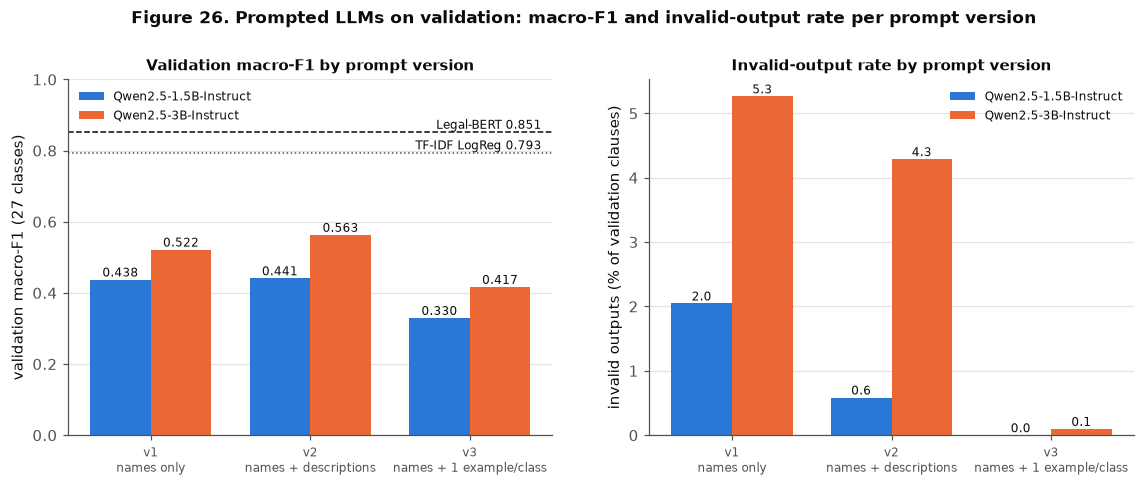

In [9]:
lb_val = float(pd.read_csv(C.RESULTS_DIR / "transformer_search.csv").set_index("run_id").loc["legalbert_lr5e-05_s42", "val_macro_f1"])
cl_val = json.loads(pd.read_csv(C.RESULTS_DIR / "test_eval_log.csv").set_index("model").loc["tfidf_logreg", "config"])["val_macro_f1"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
w = 0.38; x = np.arange(len(VERSIONS))
for i, (key, col) in enumerate([("qwen25_1p5b", PL.BLUE), ("qwen25_3b", PL.ORANGE)]):
    t = VAL_TAB[VAL_TAB.key == key].set_index("version").loc[VERSIONS]
    b = axes[0].bar(x + (i - 0.5) * w, t["macro-F1"], w, color=col, label=NICE[key])
    axes[0].bar_label(b, fmt="%.3f", fontsize=8)
    b2 = axes[1].bar(x + (i - 0.5) * w, t["invalid %"], w, color=col, label=NICE[key])
    axes[1].bar_label(b2, fmt="%.1f", fontsize=8)
axes[0].axhline(lb_val, color=PL.INK, linestyle="--", linewidth=1); axes[0].text(2.45, lb_val + 0.01, f"Legal-BERT {lb_val:.3f}", ha="right", fontsize=8)
axes[0].axhline(cl_val, color=PL.INK_2, linestyle=":", linewidth=1); axes[0].text(2.45, cl_val + 0.01, f"TF-IDF LogReg {cl_val:.3f}", ha="right", fontsize=8)
labels_x = ["v1\nnames only", "v2\nnames + descriptions", "v3\nnames + 1 example/class"]
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(labels_x, fontsize=8); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("validation macro-F1 (27 classes)"); axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8, loc="upper left")
axes[1].set_ylabel("invalid outputs (% of validation clauses)"); axes[1].legend(fontsize=8)
axes[0].set_title("Validation macro-F1 by prompt version", fontsize=10); axes[1].set_title("Invalid-output rate by prompt version", fontsize=10)
fig.suptitle("Figure 26. Prompted LLMs on validation: macro-F1 and invalid-output rate per prompt version", fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 26, "llm_validation_versions"); plt.show()

In [10]:
# What do the invalid outputs look like? (validation)
for key in MODELS:
    for v in VERSIONS:
        raw, rule = VAL_RAW[(key, v)], pd.Series(VAL_RULE[(key, v)], index=VAL_RAW[(key, v)].index)
        bad = raw[rule.values == "ambiguous"].output.tolist() + raw[rule.values == "no label"].output.tolist()
        if bad:
            top = pd.Series([b.strip()[:70] for b in bad]).value_counts().head(5)
            print(f"{NICE[key]} {v}: {len(bad)} invalid ({(rule == 'ambiguous').sum()} name two labels, {(rule == 'no label').sum()} name none). Most frequent:")
            for t_, n_ in top.items():
                print(f"     {n_:>3} x  {t_!r}")

Qwen2.5-1.5B-Instruct v1: 21 invalid (0 name two labels, 21 name none). Most frequent:
       6 x  'Non-Assignment'
       2 x  'Non-Exclusive License'
       2 x  'Arbitration Clause'
       2 x  'Non-Solicit Of Employees'
       1 x  'Data Protection'
Qwen2.5-1.5B-Instruct v2: 6 invalid (0 name two labels, 6 name none). Most frequent:
       1 x  'IntellectualPropertyOwnershipAssignment'
       1 x  'Exclusion Of Price Adjustment'
       1 x  'Supply Failure Event Definition'
       1 x  'IntellectualPropertyAssignment'
       1 x  'Notice Period'
Qwen2.5-3B-Instruct v1: 54 invalid (0 name two labels, 54 name none). Most frequent:
      10 x  'Non-Assignment'
       5 x  'Non-Solicit Of Employees'
       2 x  'Royalty Duration'
       2 x  'Arbitration'
       2 x  'Non-Solicitation Of Employees'
Qwen2.5-3B-Instruct v2: 44 invalid (0 name two labels, 44 name none). Most frequent:
       7 x  'Non-Solicitation Of Employees'
       5 x  'Royalty Duration'
       3 x  'Royalty Payment'


**Interpretation (`results/llm_validation_summary.csv`, Figure 26).**
* **Size matters most.** With every prompt version, the 3B model beats the 1.5B model on validation macro-F1: v1 0.522 vs 0.438,
  v2 0.563 vs 0.441, v3 0.417 vs 0.330.
* **Descriptions help a little; the few-shot prompt hurts.** v2 (one-line descriptions) is the best version for **both** models
  and is chosen for the test run. The gain over names only is small for the 1.5B model (+0.004) and larger for the 3B model
  (+0.041). The few-shot prompt v3 is clearly the worst for both (−0.11 and −0.15 against v2). Its predictions collapse onto a few
  labels: on validation the 3B model answers *Non-Compete* for 417 of 1,026 clauses, and the 1.5B model over-uses
  *Anti-Assignment* (200) and *Termination For Convenience* (128). A block of 27 examples (about 1,900 extra tokens) seems to
  distract these small models more than it informs them. Section 6.2 shows that the problem is the *fixed* block, not
  few-shot prompting itself: three *relevant* examples raise the 3B model to 0.694 on validation.
* **Prompt length costs time.** The fixed prompt grows from 216 tokens (v1) to 663 (v2) and 1,895 (v3); GPU time per clause grows
  with it, 0.016 → 0.035 → 0.107 s (1.5B) and 0.028 → 0.069 → 0.200 s (3B).
* **Invalid outputs are rare and almost never ambiguous.** 0.6 % (1.5B) and 4.3 % (3B) of the validation answers are invalid
  with the chosen prompt. Every invalid answer names *no* label at all (none names two). They are plausible legal labels that
  are simply not on our list: "Non-Solicitation Of Employees" (the list says *No-Solicit Of Employees*), "Non-Assignment",
  "Royalty Duration", "Royalty Payment". More than 94 % of the answers match a label exactly, so the parser rarely has to guess.

## 6. Optional analysis (VALIDATION ONLY): constrained label scoring
*Clearly an extra analysis; it is not used to choose anything and it is not run on test.* How much of the gap to the
fine-tuned model is caused by **invalid or off-list answers** rather than by not knowing the category? Instead of letting
the model write freely, we compute for every clause the log-probability that the model's answer is **exactly** each of the
27 label names followed by its end-of-turn token (`L.Runner.label_scores`; the prompt is encoded once and shared by the 27
candidates) and pick the most probable label. This can never be invalid. We also report a *hybrid*: free generation, with
only the invalid answers replaced by the constrained choice. Run with the chosen prompt of each model
(`python scripts/run_llm.py --constrained <model> <version>`).

In [11]:
cons_rows = []
for key in MODELS:
    v = CHOICE[key]["version"]
    f = LLM_DIR / f"{key}_{v}_validation_constrained.csv"
    if not f.exists():
        print(f"{f.name} missing - run scripts/run_llm.py --constrained {key} {v}"); continue
    cons = pd.read_csv(f).drop_duplicates("row_id").set_index("row_id").loc[val.row_id]
    free = np.array(VAL_PRED[(key, v)])
    hybrid = np.where(free == L.INVALID, cons.pred.values, free)
    for label, pred in [("free generation (as in the main table)", free), ("constrained label scoring", cons.pred.values),
                        ("hybrid: free, invalid -> constrained", hybrid)]:
        cons_rows.append({"model": NICE[key], "version": v, "decoding": label,
                          "macro-F1": C.compute_metrics(val.category, pred, LABELS, "x", "validation", save=False)["macro_f1"],
                          "accuracy": float((pred == val.category.values).mean()), "invalid %": 100 * float((pred == L.INVALID).mean())})
    agree = float((cons.pred.values[free != L.INVALID] == free[free != L.INVALID]).mean())
    print(f"{NICE[key]} {v}: constrained choice = free answer on {100 * agree:.1f} % of the valid free answers; "
          f"{json.load(open(LLM_DIR / 'run_meta.json'))[f'{key}_{v}_validation_constrained']['seconds']:.0f} s for {len(val)} clauses")
CONS = pd.DataFrame(cons_rows)
if len(CONS):
    CONS.to_csv(C.RESULTS_DIR / "llm_constrained_validation.csv", index=False)
    display(CONS.round(4))

Qwen2.5-1.5B-Instruct v2: constrained choice = free answer on 98.1 % of the valid free answers; 96 s for 1026 clauses
Qwen2.5-3B-Instruct v2: constrained choice = free answer on 98.0 % of the valid free answers; 169 s for 1026 clauses


,model,version,decoding,macro-F1,accuracy,invalid %
0,Qwen2.5-1.5B-Instruct,v2,free generation (as in the main table),0.4412,0.5341,0.5848
1,Qwen2.5-1.5B-Instruct,v2,constrained label scoring,0.4392,0.5351,0.0000
2,Qwen2.5-1.5B-Instruct,v2,"hybrid: free, invalid -> constrained",0.4401,0.5341,0.0000
3,Qwen2.5-3B-Instruct,v2,free generation (as in the main table),0.5632,0.6326,4.2885
4,Qwen2.5-3B-Instruct,v2,constrained label scoring,0.5680,0.6481,0.0000
5,Qwen2.5-3B-Instruct,v2,"hybrid: free, invalid -> constrained",0.5711,0.6491,0.0000


**Interpretation (`results/llm_constrained_validation.csv`; validation only, not used for any choice).** Forcing the answer to be
one of the 27 labels changes almost nothing: macro-F1 0.441 → 0.439 (1.5B) and 0.563 → 0.568 (3B). Replacing only the invalid
answers by the constrained choice gives 0.440 and 0.571. The constrained choice agrees with the free answer on 98 % of the valid
answers, which also confirms that greedy generation already picks the most likely label. **So invalid outputs explain less than
0.01 of the gap of about 0.3 to the fine-tuned model:** the models really do not know which of our 27 categories a clause
belongs to. They are not failing to format a correct answer.

### 6.2 Optional analysis (VALIDATION ONLY): retrieval few-shot prompt v4 (Qwen2.5-3B only)
*An extra analysis, not used for any choice and never run on test.* Why did the fixed few-shot
block (v3) hurt? v3 shows one *typical* example of every category — 27 examples, about 1,900 tokens, mostly unrelated to the
clause at hand. Prompt **v4** keeps the v2 descriptions and adds only the **3 most similar TRAIN clauses** (TF-IDF cosine,
`L.Retriever`; each shortened to its first 80 words) with their labels, so the examples are few, short and relevant.
Run with `python scripts/run_llm.py --retrieval` (the GPU was shared with the LEDGAR training job during this run, so its
speed is not comparable). **The tested model stays v2** whatever the result, because the prompt choice was made before.

In [12]:
v4f = LLM_DIR / "qwen25_3b_v4_validation.csv"
if v4f.exists():
    raw4, pred4, rule4 = load_raw("qwen25_3b", "v4", "validation")
    m4 = C.compute_metrics(val.category, pred4, LABELS, "qwen25_3b_v4", "validation", robust_labels=ROBUST)
    pd.DataFrame({"row_id": val.row_id, "contract": val.contract, "true": val.category, "pred": pred4, "raw_output": raw4.output.values,
                  "rule": rule4}).to_csv(C.RESULTS_DIR / "predictions" / "qwen25_3b_v4_validation.csv", index=False)
    nb4 = pd.read_csv(LLM_DIR / "qwen25_3b_v4_validation_neighbours.csv").set_index("row_id").loc[val.row_id]
    nb_lab = nb4.neighbour_labels.str.split("|")
    top1 = np.array([l[0] for l in nb_lab]); anyk = np.array([t in l for t, l in zip(val.category, nb_lab)])
    rows4 = [r for r in VAL_TAB[VAL_TAB.key == "qwen25_3b"].to_dict(orient="records")]
    rows4.append({"model": NICE["qwen25_3b"], "key": "qwen25_3b", "version": "v4 (analysis)", "macro-F1": m4["macro_f1"],
                  "macro-F1 (24 robust classes)": m4["macro_f1_robust"], "accuracy": m4["accuracy"],
                  "invalid %": 100 * float((np.array(pred4) == L.INVALID).mean()), "mean prompt tokens": float(raw4.prompt_tokens.mean())})
    V4 = pd.DataFrame(rows4)[["version", "macro-F1", "macro-F1 (24 robust classes)", "accuracy", "invalid %", "mean prompt tokens"]]
    V4.to_csv(C.RESULTS_DIR / "llm_retrieval_v4_validation.csv", index=False)
    display(V4.round(4))
    agree_top1 = float((np.array(pred4) == top1).mean())
    print(f"Retrieval quality: the nearest training clause has the right label for {100 * (top1 == val.category.values).mean():.1f} % of "
          f"validation clauses; one of the 3 neighbours has it for {100 * anyk.mean():.1f} %.")
    print(f"The v4 answer equals the label of the nearest neighbour for {100 * agree_top1:.1f} % of clauses; when the true label is "
          f"among the neighbours v4 is right for {100 * (np.array(pred4)[anyk] == val.category.values[anyk]).mean():.1f} %, otherwise for "
          f"{100 * (np.array(pred4)[~anyk] == val.category.values[~anyk]).mean():.1f} %.")
    print("Most predicted labels v3:", pd.Series(VAL_PRED[("qwen25_3b", "v3")]).value_counts().head(3).to_dict(),
          "| v4:", pd.Series(pred4).value_counts().head(3).to_dict())
    json.dump({"v4_val_macro_f1": m4["macro_f1"], "v2_val_macro_f1": CHOICE["qwen25_3b"]["val_macro_f1"],
               "nearest_label_correct": float((top1 == val.category.values).mean()), "true_label_in_top3": float(anyk.mean()),
               "v4_equals_nearest_label": agree_top1, "tested_model_unchanged": "qwen25_3b_v2"},
              open(C.RESULTS_DIR / "llm_retrieval_v4_summary.json", "w"), indent=2)
else:
    print("v4 outputs not found - run scripts/run_llm.py --retrieval")

,version,macro-F1,macro-F1 (24 robust classes),accuracy,invalid %,mean prompt tokens
0,v1,0.5219,0.5048,0.6043,5.2632,281.9776
1,v2,0.5632,0.5568,0.6326,4.2885,728.9776
2,v3,0.4169,0.3947,0.4055,0.0975,1960.9776
3,v4 (analysis),0.6943,0.6779,0.7534,0.0975,925.8392


Retrieval quality: the nearest training clause has the right label for 71.6 % of validation clauses; one of the 3 neighbours has it for 82.5 %.
The v4 answer equals the label of the nearest neighbour for 82.1 % of clauses; when the true label is among the neighbours v4 is right for 89.4 %, otherwise for 9.4 %.
Most predicted labels v3: {'Non-Compete': 417, 'Non-Transferable License': 90, 'Anti-Assignment': 73} | v4: {'Anti-Assignment': 117, 'Audit Rights': 99, 'Cap On Liability': 85}


In [13]:
# How much of v4 is retrieval? Two baselines WITHOUT any LLM, using exactly the same retriever and neighbours (validation only)
if v4f.exists():
    nn1 = np.array([l[0] for l in nb_lab])
    def vote(labels):                                   # majority of the 3 neighbours; no majority -> nearest neighbour
        c = pd.Series(labels).value_counts()
        return c.index[0] if c.iloc[0] > 1 else labels[0]
    nn3 = np.array([vote(l) for l in nb_lab])
    rows_nn = []
    for label, pred in [("v2 (LLM, descriptions only)", np.array(VAL_PRED[("qwen25_3b", "v2")])),
                        ("nearest-neighbour label (no LLM)", nn1), ("majority of 3 neighbours (no LLM)", nn3),
                        ("v4 (LLM + 3 neighbours)", np.array(pred4))]:
        m_ = C.compute_metrics(val.category, pred, LABELS, "x", "validation", save=False, robust_labels=ROBUST)
        rows_nn.append({"method": label, "validation macro-F1": m_["macro_f1"], "macro-F1 (24 robust)": m_["macro_f1_robust"],
                        "accuracy": m_["accuracy"]})
    NN = pd.DataFrame(rows_nn); display(NN.round(4))
    NN.to_csv(C.RESULTS_DIR / "llm_retrieval_baselines_validation.csv", index=False)
    f = dict(zip(NN.method, NN["validation macro-F1"]))
    best_nn = max(f["nearest-neighbour label (no LLM)"], f["majority of 3 neighbours (no LLM)"])
    gain = f["v4 (LLM + 3 neighbours)"] - f["v2 (LLM, descriptions only)"]
    share = (best_nn - f["v2 (LLM, descriptions only)"]) / gain
    print(f"v2 -> v4 gain: {gain:+.3f}. The better retrieval-only baseline reaches {best_nn:.3f}, i.e. {100 * share:.0f} % of the v2->v4 gain "
          f"without any LLM; the LLM adds {f['v4 (LLM + 3 neighbours)'] - best_nn:+.3f} on top of retrieval alone.")
    s4 = json.load(open(C.RESULTS_DIR / "llm_retrieval_v4_summary.json"))
    s4.update({"nn1_val_macro_f1": f["nearest-neighbour label (no LLM)"], "nn3_vote_val_macro_f1": f["majority of 3 neighbours (no LLM)"],
               "share_of_v4_gain_from_retrieval": share})
    json.dump(s4, open(C.RESULTS_DIR / "llm_retrieval_v4_summary.json", "w"), indent=2)

,method,validation macro-F1,macro-F1 (24 robust),accuracy
0,"v2 (LLM, descriptions only)",0.5632,0.5568,0.6326
1,nearest-neighbour label (no LLM),0.6551,0.6394,0.7164
2,majority of 3 neighbours (no LLM),0.6610,0.6390,0.7339
3,v4 (LLM + 3 neighbours),0.6943,0.6779,0.7534


v2 -> v4 gain: +0.131. The better retrieval-only baseline reaches 0.661, i.e. 75 % of the v2->v4 gain without any LLM; the LLM adds +0.033 on top of retrieval alone.


**Interpretation (`results/llm_retrieval_v4_validation.csv`; validation only, analysis).** With the v2 descriptions plus the
**3 most similar training clauses**, Qwen2.5-3B reaches **0.694** validation macro-F1: +0.131 over v2 (0.563) and +0.277 over
the fixed few-shot block v3 (0.417). Invalid answers drop to 0.1 %, and the prompt is shorter than v3 (926 vs 1,961 tokens on
average). This explains why v3 hurt. Its 27 examples are mostly irrelevant to the clause, long, and always in the same order, and
the small model latches onto one of them (*Non-Compete* for 417 clauses). In v4 the few examples are the *nearest* ones. The
model then largely copies the nearest neighbour's label: v4's answer equals the label of the most similar training clause for
82 % of clauses, and when the true label is among the three neighbours (82.5 % of clauses) v4 is right 89 % of the time, against
only 9 % otherwise. The retrieval-only baselines (no LLM, same retriever, `results/llm_retrieval_baselines_validation.csv`)
confirm this: the nearest training clause's label alone gives **0.655** macro-F1 and a majority vote of the 3 neighbours
**0.661**, so about **75 %** of the v2 → v4 gain (+0.131) is achieved by retrieval alone. The LLM adds only +0.033 on top, by
choosing among the neighbours' labels with the help of the descriptions. v4 is thus essentially a nearest-neighbour classifier
with the LLM as a judge, and its success says more about the value of labelled examples than about the LLM's own
understanding of the categories. **As decided before this
analysis, the tested model stays v2** (one test evaluation per model); v4 was not run on test, and its validation score is
not a test result.

## 7. Test evaluation (once per model)
The chosen version of each model is run on the 1,444 test clauses (`scripts/run_llm.py --test`, only if its outputs are not
yet saved) and scored **once** through `C.test_once` (model names `qwen25_1p5b_<version>`, `qwen25_3b_<version>`).
Confidence intervals resample **contracts** (93 test contracts; point estimate over all 27 classes, each resample averages
over the classes present in it). Paired bootstraps compare models on the same resampled contracts.

In [14]:
TEST_PRED, TEST_RES, TEST_RAW = {}, {}, {}
for key in MODELS:
    v = CHOICE[key]["version"]
    f = LLM_DIR / f"{key}_{v}_test.csv"
    if not f.exists() or pd.read_csv(f).row_id.nunique() < len(test):
        subprocess.run([sys.executable, "scripts/run_llm.py", "--test", key, v], check=True)
    raw, pred, rule = load_raw(key, v, "test")
    name = f"{key}_{v}"
    cfg = {"model_id": MODELS[key], "prompt_version": v, "prompt": L.VERSIONS[v], "decoding": "greedy, max_new_tokens 24",
           "selected_on": "validation macro-F1", "val_macro_f1": CHOICE[key]["val_macro_f1"], "parser": "src/llm.py parse_label"}
    TEST_RES[key] = C.test_once(name, cfg, test.category, pred, LABELS, test.row_id, test.contract, ROBUST)
    TEST_PRED[key], TEST_RAW[key] = np.array(pred), raw
    print(f"{NICE[key]} ({v}): test macro-F1 {TEST_RES[key]['macro_f1']:.4f} | invalid {100 * (np.array(pred) == L.INVALID).mean():.1f} %")

[test] qwen25_1p5b_v2: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.
Qwen2.5-1.5B-Instruct (v2): test macro-F1 0.4508 | invalid 0.6 %
[test] qwen25_3b_v2: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.
Qwen2.5-3B-Instruct (v2): test macro-F1 0.5564 | invalid 5.1 %


In [15]:
def load_pred(name):
    p = pd.read_csv(C.RESULTS_DIR / "predictions" / f"{name}.csv").set_index("row_id").loc[test.row_id]
    return p.pred.astype(str).values
REF = {"Legal-BERT (fine-tuned)": load_pred("legalbert"), "TF-IDF + LogReg (best classical)": load_pred("tfidf_logreg"),
       "BERT-base (fine-tuned)": load_pred("bert_base")}
ALL = {**REF, **{f"{NICE[k]} ({CHOICE[k]['version']})": TEST_PRED[k] for k in MODELS}}
yt = test.category.values
rows = []
for name, pred in ALL.items():
    m = C.compute_metrics(yt, pred, LABELS, "x", "test", save=False, robust_labels=ROBUST)
    ci = C.bootstrap_ci(yt, pred, test.contract.values, labels=LABELS)
    rows.append({"model": name, "macro-F1": m["macro_f1"], "95% CI": f"[{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]",
                 "macro-F1 (24 robust classes)": m["macro_f1_robust"], "accuracy": m["accuracy"], "weighted-F1": m["weighted_f1"],
                 "invalid %": 100 * float((pred == L.INVALID).mean())})
TEST_TAB = pd.DataFrame(rows); display(TEST_TAB.round(4))
q15, q3 = [f"{NICE[k]} ({CHOICE[k]['version']})" for k in MODELS]
pairs = [("Legal-BERT (fine-tuned)", q15), ("Legal-BERT (fine-tuned)", q3), (q3, q15), ("TF-IDF + LogReg (best classical)", q3)]
PB = []
for a, b in pairs:
    r = C.paired_bootstrap(yt, ALL[a], ALL[b], test.contract.values, labels=LABELS)
    PB.append({"A": a, "B": b, "macro-F1 A - B": r["diff"], "95% CI": f"[{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]",
               "share of resamples A not better": r["p_a_not_better"], **{k: r[k] for k in ["ci_low", "ci_high"]}})
PB = pd.DataFrame(PB); display(PB.drop(columns=["ci_low", "ci_high"]).round(4))
TEST_TAB.to_csv(C.RESULTS_DIR / "llm_test_comparison.csv", index=False)
PB.to_csv(C.RESULTS_DIR / "llm_paired_bootstrap.csv", index=False)

,model,macro-F1,95% CI,macro-F1 (24 robust classes),accuracy,weighted-F1,invalid %
0,Legal-BERT (fine-tuned),0.8708,"[0.836, 0.896]",0.8661,0.8906,0.8897,0.0000
1,TF-IDF + LogReg (best classical),0.7939,"[0.752, 0.824]",0.7962,0.8289,0.8300,0.0000
2,BERT-base (fine-tuned),0.8256,"[0.796, 0.857]",0.8302,0.8615,0.8600,0.0000
3,Qwen2.5-1.5B-Instruct (v2),0.4508,"[0.407, 0.475]",0.4311,0.5284,0.5061,0.5540
4,Qwen2.5-3B-Instruct (v2),0.5564,"[0.518, 0.587]",0.5499,0.6115,0.6312,5.0554


,A,B,macro-F1 A - B,95% CI,share of resamples A not better
0,Legal-BERT (fine-tuned),Qwen2.5-1.5B-Instruct (v2),0.4200,"[+0.386, +0.467]",0.0
1,Legal-BERT (fine-tuned),Qwen2.5-3B-Instruct (v2),0.3144,"[+0.274, +0.351]",0.0
2,Qwen2.5-3B-Instruct (v2),Qwen2.5-1.5B-Instruct (v2),0.1056,"[+0.081, +0.144]",0.0
3,TF-IDF + LogReg (best classical),Qwen2.5-3B-Instruct (v2),0.2375,"[+0.195, +0.281]",0.0


**Interpretation (`results/llm_test_comparison.csv`, `results/llm_paired_bootstrap.csv`).** On the 1,444 test clauses the
chosen prompts score **0.451** [0.407, 0.475] (Qwen2.5-1.5B, v2) and **0.556** [0.518, 0.587] (Qwen2.5-3B, v2), close to their
validation scores (0.441 and 0.563), so the prompt choice did not over-fit validation. Invalid answers: 0.6 % and 5.1 %. The
fine-tuned Legal-BERT (0.871) is far better than both: **+0.420** [+0.386, +0.467] over the 1.5B model and **+0.314** [+0.274,
+0.351] over the 3B model. Even the TF-IDF + logistic regression baseline (0.794) beats the 3B model by +0.238 [+0.195, +0.281].
Doubling the model size helps clearly: 3B − 1.5B = **+0.106** [+0.081, +0.144]. In every comparison the confidence interval
excludes 0 (no resample reverses the order). The robustness number over the 24 classes with ≥ 15 test clauses tells the same
story (0.431 and 0.550 vs 0.866 for Legal-BERT).

## 8. Which classes do the prompted models handle, and which do they confuse?

In [16]:
pc = pd.DataFrame(index=LABELS)
pc["test clauses"] = test.category.value_counts().reindex(LABELS)
pc["Legal-BERT F1"] = pd.Series(C.compute_metrics(yt, REF["Legal-BERT (fine-tuned)"], LABELS, "x", "test", save=False)["per_class"]).map(lambda d: d["f1"])
for key in MODELS:
    m = TEST_RES[key]["per_class"]
    pc[f"{NICE[key]} F1"] = [m[l]["f1"] for l in LABELS]
    pc[f"{NICE[key]} recall"] = [m[l]["recall"] for l in LABELS]
    ci = C.per_class_bootstrap_ci(yt, TEST_PRED[key], test.contract.values, LABELS)
    pc[f"{NICE[key]} F1 95% CI"] = [f"[{ci.loc[l, 'ci_low']:.2f}, {ci.loc[l, 'ci_high']:.2f}]" if ci.loc[l, "ci_low"] == ci.loc[l, "ci_low"]
                                    else "not estimable" for l in LABELS]
best_key = max(MODELS, key=lambda k: TEST_RES[k]["macro_f1"])
pc = pc.sort_values(f"{NICE[best_key]} F1")
pc.to_csv(C.RESULTS_DIR / "llm_per_class.csv")
display(pc.round(3))

,test clauses,Legal-BERT F1,Qwen2.5-1.5B-Instruct F1,Qwen2.5-1.5B-Instruct recall,Qwen2.5-1.5B-Instruct F1 95% CI,Qwen2.5-3B-Instruct F1,Qwen2.5-3B-Instruct recall,Qwen2.5-3B-Instruct F1 95% CI
Competitive Restriction Exception,17,0.757,0.138,0.235,"[0.00, 0.28]",0.000,0.000,"[0.00, 0.00]"
Post-Termination Services,70,0.838,0.056,0.029,"[0.00, 0.13]",0.082,0.043,"[0.00, 0.15]"
Non-Transferable License,19,0.611,0.333,0.263,"[0.00, 0.56]",0.169,0.579,"[0.06, 0.29]"
Volume Restriction,31,0.952,0.136,0.097,"[0.00, 0.30]",0.203,0.226,"[0.04, 0.35]"
Non-Disparagement,12,0.857,0.435,0.417,"[0.18, 0.67]",0.219,0.667,"[0.08, 0.33]"
Rofr/Rofo/Rofn,62,0.848,0.211,0.129,"[0.05, 0.40]",0.225,0.129,"[0.07, 0.41]"
Warranty Duration,18,0.944,0.414,0.667,"[0.17, 0.60]",0.329,0.722,"[0.14, 0.49]"
Non-Compete,48,0.866,0.374,0.479,"[0.25, 0.48]",0.416,0.333,"[0.26, 0.59]"
Exclusivity,44,0.738,0.226,0.409,"[0.13, 0.34]",0.456,0.591,"[0.34, 0.55]"
Covenant Not To Sue,43,0.913,0.387,0.279,"[0.20, 0.56]",0.533,0.372,"[0.33, 0.70]"


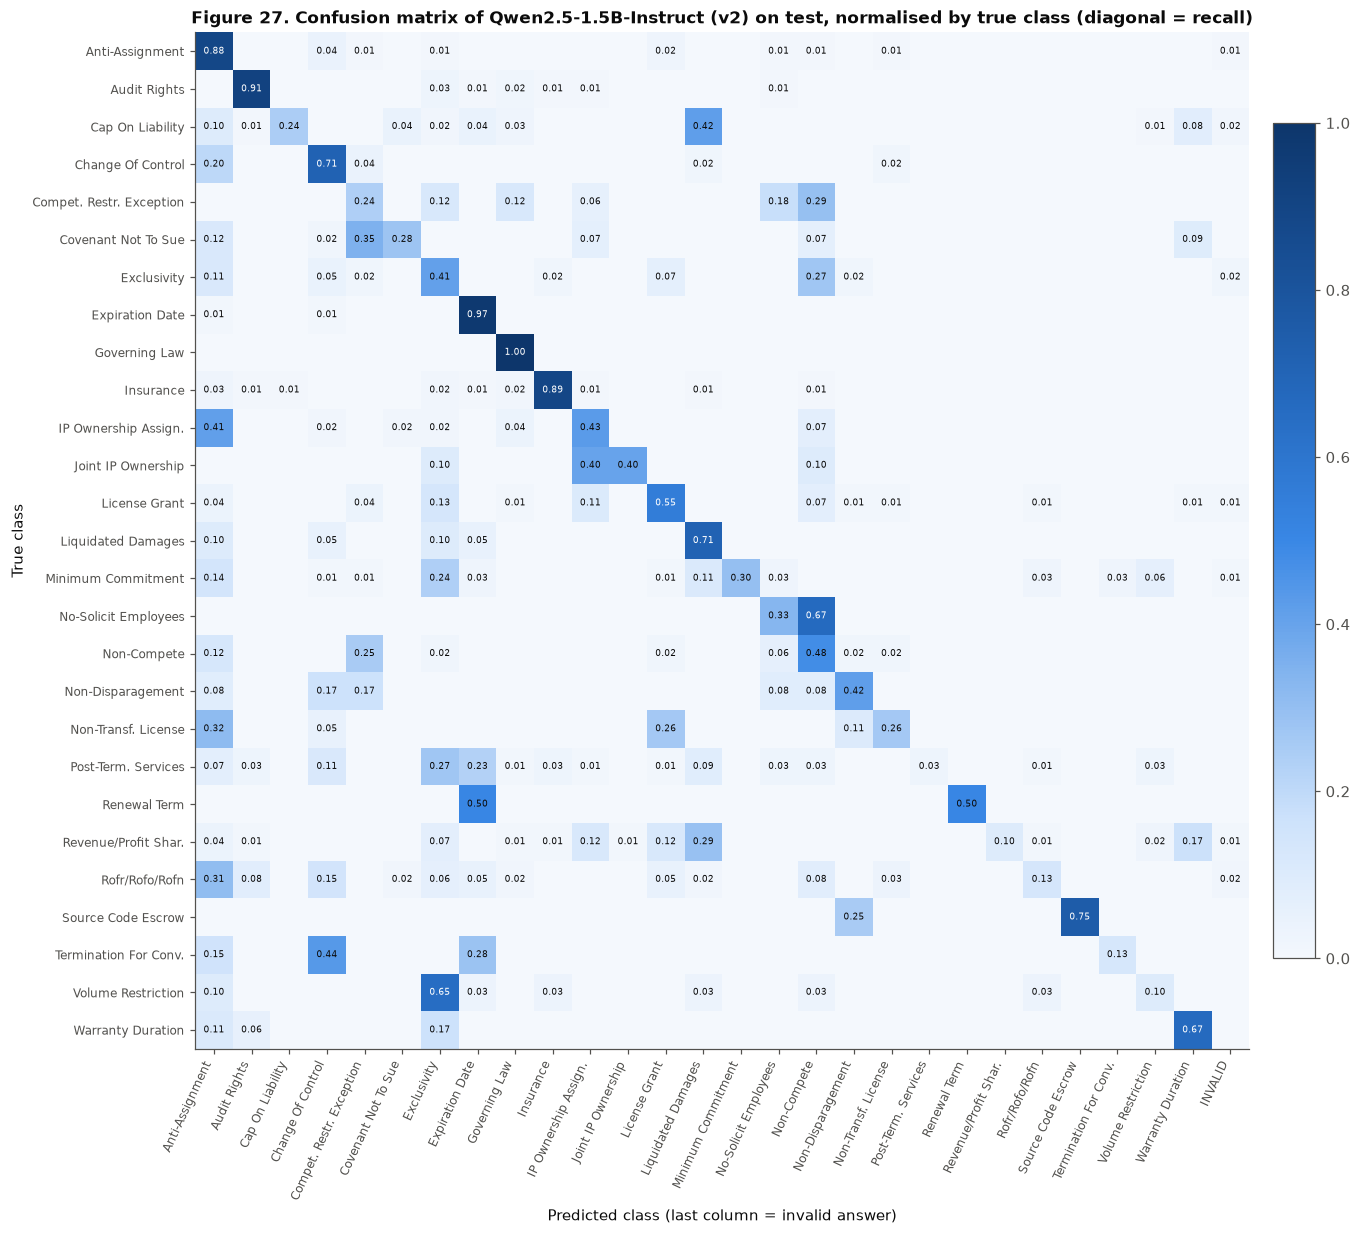

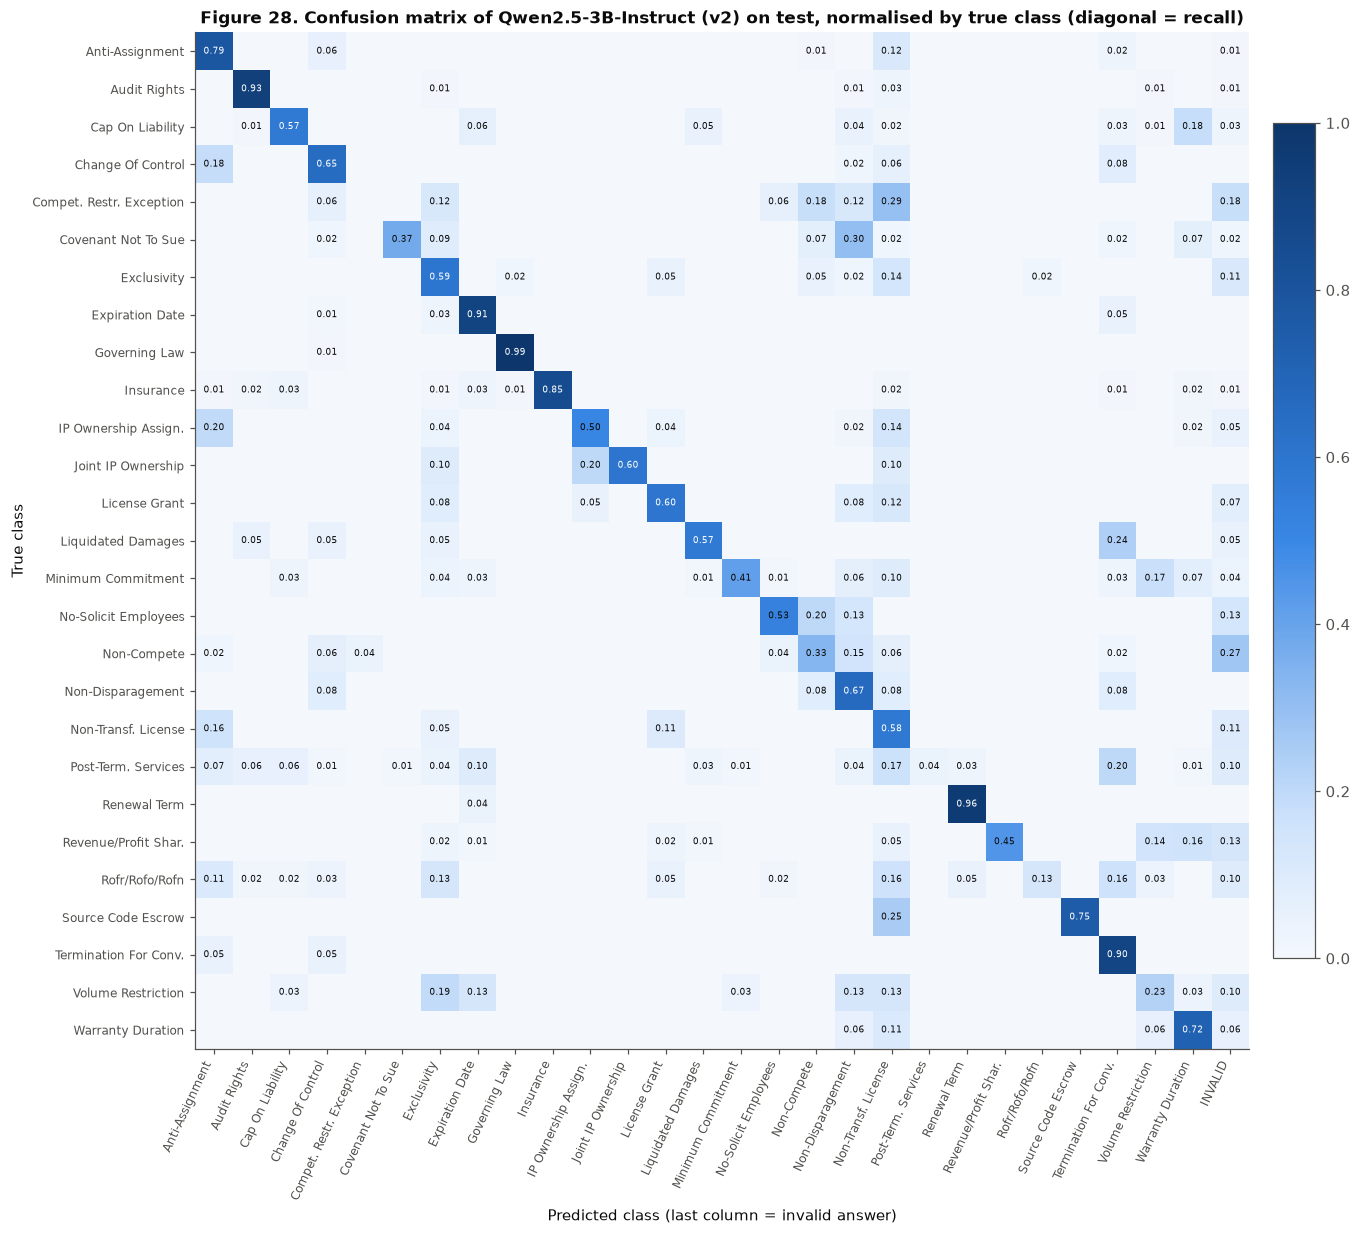

In [17]:
SHORT = {"Post-Termination Services": "Post-Term. Services", "Termination For Convenience": "Termination For Conv.",
         "Ip Ownership Assignment": "IP Ownership Assign.", "Revenue/Profit Sharing": "Revenue/Profit Shar.",
         "Competitive Restriction Exception": "Compet. Restr. Exception", "Non-Transferable License": "Non-Transf. License",
         "No-Solicit Of Employees": "No-Solicit Employees", "Joint Ip Ownership": "Joint IP Ownership"}
short = [SHORT.get(l, l) for l in LABELS] + ["INVALID"]
def plot_cm_llm(pred, title, number, fname):
    cmx = pd.crosstab(pd.Categorical(yt, LABELS), pd.Categorical(pred, LABELS + [L.INVALID]), dropna=False).values
    mat = cmx / cmx.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(14, 12))
    im = ax.imshow(mat, cmap=PL.BLUES, vmin=0, vmax=1)
    ax.set_xticks(range(len(short))); ax.set_xticklabels(short, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(short[:-1], fontsize=8)
    ax.set_xlabel("Predicted class (last column = invalid answer)"); ax.set_ylabel("True class"); ax.grid(False)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if mat[i, j] > 0:
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if mat[i, j] > 0.55 else PL.INK)
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); ax.set_title(title, fontsize=11)
    PL.savefig(fig, number, fname); plt.show()
    return pd.DataFrame(cmx, index=LABELS, columns=LABELS + [L.INVALID])
CM = {}
for key, num in [("qwen25_1p5b", 27), ("qwen25_3b", 28)]:
    CM[key] = plot_cm_llm(TEST_PRED[key], f"Figure {num}. Confusion matrix of {NICE[key]} ({CHOICE[key]['version']}) on test, "
                          "normalised by true class (diagonal = recall)", num, f"cm_{key}_normalised")

In [18]:
# Most frequent confusions of each model on test, and where the predictions pile up
for key in MODELS:
    cmx = CM[key]
    pairs_ = [(t, p, int(cmx.loc[t, p])) for t in LABELS for p in LABELS + [L.INVALID] if t != p and cmx.loc[t, p] > 0]
    top = pd.DataFrame(pairs_, columns=["true", "predicted", "clauses"]).sort_values("clauses", ascending=False).head(8)
    print(f"--- {NICE[key]} ({CHOICE[key]['version']}): most frequent confusions ---"); display(top.reset_index(drop=True))
    over = pd.Series(TEST_PRED[key]).value_counts().head(5)
    print("Most predicted labels:", {k: f"{v} predicted / {int((yt == k).sum())} true" for k, v in over.items()})

--- Qwen2.5-1.5B-Instruct (v2): most frequent confusions ---


,true,predicted,clauses
0,Cap On Liability,Liquidated Damages,48
1,Revenue/Profit Sharing,Liquidated Damages,24
2,Ip Ownership Assignment,Anti-Assignment,23
3,Volume Restriction,Exclusivity,20
4,Minimum Commitment,Exclusivity,19
5,Post-Termination Services,Exclusivity,19
6,Rofr/Rofo/Rofn,Anti-Assignment,19
7,Termination For Convenience,Change Of Control,17


Most predicted labels: {'Anti-Assignment': '232 predicted / 121 true', 'Expiration Date': '125 predicted / 74 true', 'Exclusivity': '115 predicted / 44 true', 'Insurance': '109 predicted / 116 true', 'Liquidated Damages': '106 predicted / 21 true'}
--- Qwen2.5-3B-Instruct (v2): most frequent confusions ---


,true,predicted,clauses
0,Cap On Liability,Warranty Duration,21
1,Anti-Assignment,Non-Transferable License,14
2,Post-Termination Services,Termination For Convenience,14
3,Minimum Commitment,Volume Restriction,14
4,Covenant Not To Sue,Non-Disparagement,13
5,Non-Compete,INVALID,13
6,Revenue/Profit Sharing,Warranty Duration,13
7,Post-Termination Services,Non-Transferable License,12


Most predicted labels: {'Anti-Assignment': '134 predicted / 121 true', 'Non-Transferable License': '111 predicted / 19 true', 'Audit Rights': '103 predicted / 101 true', 'Insurance': '99 predicted / 116 true', 'Expiration Date': '92 predicted / 74 true'}


In [19]:
# How much do descriptions / few-shot examples help per class? (validation, both models: F1 per version)
rows = []
for key in MODELS:
    for v in VERSIONS:
        per = C.compute_metrics(val.category, VAL_PRED[(key, v)], LABELS, "x", "validation", save=False)["per_class"]
        rows += [{"model": NICE[key], "version": v, "class": l, "F1": per[l]["f1"]} for l in LABELS]
pv = pd.DataFrame(rows).pivot_table(index="class", columns=["model", "version"], values="F1")
JARGON = ["Rofr/Rofo/Rofn", "Competitive Restriction Exception", "Volume Restriction", "Covenant Not To Sue", "Post-Termination Services",
          "Liquidated Damages", "Change Of Control", "Governing Law", "Insurance", "Audit Rights"]
display(pv.loc[JARGON].round(3))
pv.to_csv(C.RESULTS_DIR / "llm_per_class_by_version_validation.csv")

model                             Qwen2.5-1.5B-Instruct                \
version                                              v1     v2     v3   
class                                                                   
Rofr/Rofo/Rofn                                    0.240  0.386  0.128   
Competitive Restriction Exception                 0.000  0.091  0.000   
Volume Restriction                                0.250  0.235  0.286   
Covenant Not To Sue                               0.000  0.154  0.000   
Post-Termination Services                         0.000  0.038  0.000   
Liquidated Damages                                0.375  0.226  0.110   
Change Of Control                                 0.703  0.391  0.583   
Governing Law                                     0.791  0.877  0.766   
Insurance                                         0.741  0.912  0.569   
Audit Rights                                      0.852  0.943  0.885   

model                             Qwen2.5-3B-Instruct                
version                                            v1     v2     v3  
class                                                                
Rofr/Rofo/Rofn                                  0.167  0.400  0.200  
Competitive Restriction Exception               0.000  0.000  0.111  
Volume Restriction                              0.222  0.333  0.146  
Covenant Not To Sue                             0.000  0.273  0.000  
Post-Termination Services                       0.038  0.038  0.038  
Liquidated Damages                              0.606  0.600  0.333  
Change Of Control                               0.667  0.642  0.683  
Governing Law                                   0.956  0.965  0.635  
Insurance                                       0.934  0.885  0.447  
Audit Rights                                    0.930  0.948  0.838

**Interpretation (`results/llm_per_class.csv`, Figures 27–28).**
* **What prompting handles.** Categories whose names say what the clause says: *Governing Law* (3B: F1 0.98), *Audit Rights*
  (0.92), *Insurance* (0.92), *Renewal Term* (0.88), *Expiration Date* (0.81). Here the 3B model is within about 0.1 of Legal-BERT.
* **What it cannot do.** The categories defined by CUAD's annotation conventions rather than by everyday meaning:
  *Competitive Restriction Exception* (F1 0.00 for the 3B model; it is an *exception to* a restriction, and the model labels it as
  the restriction itself, e.g. *Non-Transferable License*, *Non-Compete* or *Exclusivity*), *Post-Termination Services* (0.08;
  predicted as *Termination For Convenience* or *Non-Transferable License*), *Volume Restriction* (0.20), *Rofr/Rofo/Rofn* (0.23;
  jargon), *Non-Transferable License* (0.17; massively over-predicted: 111 predictions for 19 true clauses).
* **Label semantics.** Several errors are reasonable readings of the label name that differ from CUAD's definition. A cap on
  liability that limits the *time* to bring claims is answered as *Warranty Duration* (21 of 115); a ban on soliciting employees
  is labelled *Non-Compete*; restrictions on assigning the contract become *Non-Transferable License*. A fine-tuned model learns
  CUAD's conventions from 5,315 examples; a prompted model only has the names and one-line descriptions.
* **Descriptions vs names (validation, by class).** Descriptions help most where the name is jargon or misleading: *Rofr/Rofo/Rofn*
  0.17 → 0.40 and *Covenant Not To Sue* 0.00 → 0.27 for the 3B model. They hardly change the easy classes. The 1.5B model over-uses
  *Liquidated Damages* and *Exclusivity* as "catch-all" answers (106 and 115 test predictions for 21 and 44 true clauses).

## 9. Latency, throughput, memory and cost per 1,000 clauses
All timings were measured on this machine (RTX 5080 16 GB for GPU models; the CPU for TF-IDF). **Latency** = one clause at a
time (batch size 1), on the same 100 validation clauses for every model (median and 95th percentile). **Throughput** = the
batched test run. **Cost per 1,000 clauses** = GPU (or CPU) seconds per clause × 1,000 / 3,600 × an hourly price.

**Price assumption (stated, not measured).** Primary source: Amazon Web Services, *Amazon EC2 On-Demand Pricing*
(https://aws.amazon.com/ec2/pricing/on-demand/), Linux, US East (N. Virginia), read on **2026-10-22** (values taken from the
page's published price file, publication date 2026-10-15): **g6.xlarge** (1 × NVIDIA L4, 4 vCPU, 16 GiB) **$0.8048 per hour**
for every GPU model, and **c7i.xlarge** (4 vCPU, 8 GiB) **$0.1785 per hour** for TF-IDF. Cross-checks, also read on 2026-10-22:
Holori AWS price calculator (https://calculator.holori.com/aws/ec2/g6.xlarge/us-east-1 and …/c7i.xlarge/us-east-1, pages
"last updated Oct 21, 2026") and DoiT (https://www.doit.com/compute/spot/us-east-1/g6.xlarge) give the same figures. All
sources are recorded in `results/llm_price_sources.json`. API fee = 0 (local models). **Assumption:** the L4 is a different
GPU from the RTX 5080 we measured on, so the cost is an order-of-magnitude comparison on **one common basis**, not a quote.

In [20]:
PRICES = json.load(open(C.RESULTS_DIR / "llm_price_sources.json"))
GPU_PRICE, CPU_PRICE = PRICES["primary"]["g6.xlarge"]["usd_per_hour"], PRICES["primary"]["c7i.xlarge"]["usd_per_hour"]
PRICE_SOURCE = {"primary": PRICES["primary"]["url"], "gpu_instance": "g6.xlarge (1x NVIDIA L4)", "cpu_instance": "c7i.xlarge",
                "read_on": PRICES["read_on"], "cross_checks": [c["url"] for c in PRICES["cross_checks"]]}
print(f"Prices (AWS on-demand, us-east-1, read {PRICES['read_on']}): GPU ${GPU_PRICE}/h, CPU ${CPU_PRICE}/h")
LAT_SAMPLE = val.sample(100, random_state=42)          # the same 100 clauses as scripts/run_llm.py --latency
for key in MODELS:
    v = CHOICE[key]["version"]
    if not (LLM_DIR / f"latency_{key}_{v}.json").exists():
        subprocess.run([sys.executable, "scripts/run_llm.py", "--latency", key, v], check=True)
LAT = {key: json.load(open(LLM_DIR / f"latency_{key}_{CHOICE[key]['version']}.json")) for key in MODELS}

# Legal-BERT (Task 1 test model): batch-1 latency on the same clauses + batched throughput from the logged test inference
from transformers import AutoModelForSequenceClassification
from src.preprocess import preprocess_for_transformer
from src.finetune import RECIPE as FT_RECIPE
lb_dir = ROOT / "models" / "legalbert_lr5e-05_s42" / "best"
budget = pd.read_csv(C.RESULTS_DIR / "compute_budget.csv")
lb_tp = budget[(budget.model == "legalbert") & (budget.stage == "inference_test_gpu")].seconds.iloc[0] / len(test)
if not (LLM_DIR / "latency_legalbert.json").exists() and lb_dir.exists() and torch.cuda.is_available():   # measured once
    lb_tok = AutoTokenizer.from_pretrained(lb_dir); lb = AutoModelForSequenceClassification.from_pretrained(lb_dir).to("cuda").eval()
    torch.cuda.reset_peak_memory_stats(); secs = []
    with torch.no_grad():
        for i, t in enumerate([LAT_SAMPLE.text.iloc[0]] + list(LAT_SAMPLE.text)):
            enc = lb_tok(preprocess_for_transformer(t), truncation=True, max_length=FT_RECIPE["max_length"], return_tensors="pt").to("cuda")
            torch.cuda.synchronize(); t0 = time.perf_counter()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                lb(**enc).logits.argmax(-1).item()
            torch.cuda.synchronize()
            if i:
                secs.append(time.perf_counter() - t0)
    LAT_LB = {"median_ms": 1000 * float(np.median(secs)), "p95_ms": 1000 * float(np.percentile(secs, 95)),
              "peak_gpu_mem_gb_batch1": torch.cuda.max_memory_allocated() / 1e9}
    del lb; torch.cuda.empty_cache()
    json.dump(LAT_LB, open(LLM_DIR / "latency_legalbert.json", "w"), indent=2)
else:
    LAT_LB = json.load(open(LLM_DIR / "latency_legalbert.json"))

# TF-IDF + LogReg (best classical): rebuilt with the selected configuration, checked against its saved test predictions
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from src import preprocess as P
cl_cfg = json.loads(pd.read_csv(C.RESULTS_DIR / "test_eval_log.csv").set_index("model").loc["tfidf_logreg", "config"])
pipe = make_pipeline(TfidfVectorizer(analyzer="char_wb", preprocessor=lambda s: P.clean_text(s, cl_cfg["preprocessing"]), lowercase=False,
                                     ngram_range=(3, 6), min_df=int(cl_cfg["min_df"]), max_df=float(cl_cfg["max_df"]), sublinear_tf=True),
                     LogisticRegression(C=float(cl_cfg["C_or_alpha"]), class_weight="balanced", max_iter=3000))
pipe.fit(train.text, train.category)
t0 = time.perf_counter(); cl_test_pred = pipe.predict(test.text); tp_now = (time.perf_counter() - t0) / len(test)
print("Rebuilt TF-IDF + LogReg reproduces its saved test predictions:", bool((cl_test_pred == REF["TF-IDF + LogReg (best classical)"]).all()))
cl_file = LLM_DIR / "latency_tfidf_logreg.json"
if not cl_file.exists():                          # measured once, then re-used so a re-run does not change the reported numbers
    secs = []
    for t in LAT_SAMPLE.text:
        t0 = time.perf_counter(); pipe.predict([t]); secs.append(time.perf_counter() - t0)
    json.dump({"median_ms": 1000 * float(np.median(secs)), "p95_ms": 1000 * float(np.percentile(secs, 95)),
               "throughput_seconds_per_clause": tp_now, "device": "CPU"}, open(cl_file, "w"), indent=2)
LAT_CL = json.load(open(cl_file)); cl_tp = LAT_CL["throughput_seconds_per_clause"]

Prices (AWS on-demand, us-east-1, read 2026-10-22): GPU $0.8048/h, CPU $0.1785/h


W1113 17:13:49.137000 30748 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Rebuilt TF-IDF + LogReg reproduces its saved test predictions: True


In [21]:
meta = json.load(open(LLM_DIR / "run_meta.json"))
train_s = {r.model: r.seconds for r in budget[budget.stage == "train_final"].drop_duplicates("model").itertuples()}
rows = []
def add(model, kind, tput_s, lat, peak, train_seconds, price, f1, params):
    # headline: batched cost; batch-1 cost and latency are extra columns
    rows.append({"model": model, "device": kind, "macro-F1 (test)": f1,
                 "cost per 1,000 clauses USD (batched)": tput_s * 1000 / 3600 * price,
                 "throughput clauses/s (batched)": 1 / tput_s,
                 "cost per 1,000 clauses USD (batch 1)": lat["median_ms"] / 1000 * 1000 / 3600 * price,
                 "latency median ms (batch 1)": lat["median_ms"], "latency p95 ms (batch 1)": lat["p95_ms"],
                 "peak GPU memory GB": peak, "training seconds (one-off)": train_seconds, "parameters": params})
f1 = dict(zip(TEST_TAB.model, TEST_TAB["macro-F1"]))
add("TF-IDF + LogReg (best classical)", "CPU", cl_tp, LAT_CL, 0.0, train_s.get("tfidf_logreg"), CPU_PRICE, f1["TF-IDF + LogReg (best classical)"], "69,247 features x 27")
add("Legal-BERT (fine-tuned)", "GPU", lb_tp, LAT_LB, LAT_LB["peak_gpu_mem_gb_batch1"], train_s.get("legalbert"), GPU_PRICE,
    f1["Legal-BERT (fine-tuned)"], "110 M")
for key in MODELS:
    v = CHOICE[key]["version"]; raw = TEST_RAW[key]
    add(f"{NICE[key]} ({v})", "GPU", gpu_seconds(raw) / len(raw), LAT[key], meta[f"{key}_{v}_test"]["peak_gpu_mem_gb"], 0.0, GPU_PRICE,
        f1[f"{NICE[key]} ({v})"], f"{meta[f'{key}_{v}_test']['n_params'] / 1e9:.2f} B")
COST = pd.DataFrame(rows)
with pd.option_context("display.float_format", lambda x: f"{x:.6g}"):
    display(COST)
json.dump({"price_assumption": {"gpu_usd_per_hour": GPU_PRICE, "cpu_usd_per_hour": CPU_PRICE, **PRICE_SOURCE,
                                "note": "timings measured on an RTX 5080 (GPU) / local CPU; price of a comparable cloud instance applied"},
           "api_fee": 0, "rows": COST.to_dict(orient="records")}, open(C.RESULTS_DIR / "llm_cost.json", "w"), indent=2, default=float)
# log the latency measurements once in the compute budget
if not (budget.stage == "latency_batch1").any():
    new = [{"timestamp": pd.Timestamp.now().isoformat(timespec="seconds"), "model": r["model"], "stage": "latency_batch1",
            "seconds": round(r["latency median ms (batch 1)"] / 1000 * 100, 3), "device": r["device"],
            "notes": f"100 validation clauses at batch 1 (approx. = median x 100); median {r['latency median ms (batch 1)']:.1f} ms, "
                     f"p95 {r['latency p95 ms (batch 1)']:.1f} ms"} for r in rows]
    pd.concat([budget, pd.DataFrame(new)], ignore_index=True).to_csv(C.RESULTS_DIR / "compute_budget.csv", index=False)

,model,device,macro-F1 (test),"cost per 1,000 clauses USD (batched)",throughput clauses/s (batched),"cost per 1,000 clauses USD (batch 1)",latency median ms (batch 1),latency p95 ms (batch 1),peak GPU memory GB,training seconds (one-off),parameters
0,TF-IDF + LogReg (best classical),CPU,0.793924,1.03629e-05,4784.68,2.54982e-05,0.51425,0.931285,0,6.15,"69,247 features x 27"
1,Legal-BERT (fine-tuned),GPU,0.870827,0.000216744,1031.43,0.00129347,5.7859,6.52411,0.646352,94.25,110 M
2,Qwen2.5-1.5B-Instruct (v2),GPU,0.450803,0.0080696,27.7034,0.0280699,125.561,171.035,6.98801,0,1.54 B
3,Qwen2.5-3B-Instruct (v2),GPU,0.556399,0.0153635,14.5511,0.0425149,190.176,256.925,11.1772,0,3.09 B


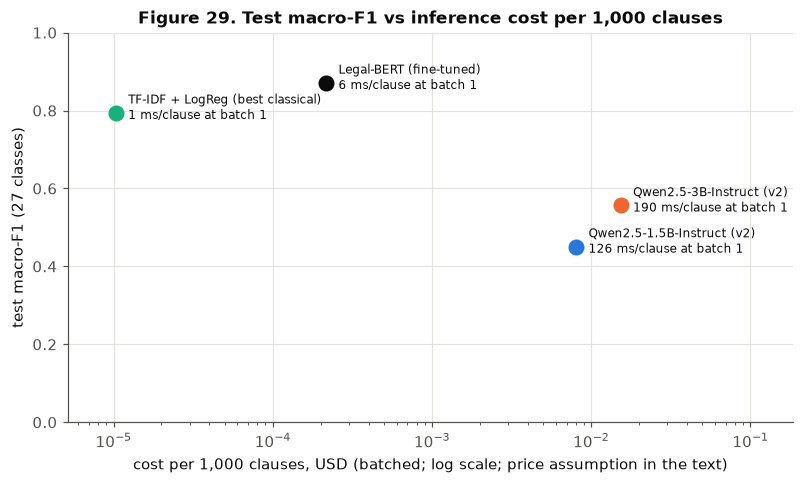

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
cols = [PL.AQUA, PL.INK, PL.BLUE, PL.ORANGE]
for (_, r), col in zip(COST.iterrows(), cols):
    ax.scatter(r["cost per 1,000 clauses USD (batched)"], r["macro-F1 (test)"], s=90, color=col, zorder=3)
    ax.annotate(f"{r['model']}\n{r['latency median ms (batch 1)']:.0f} ms/clause at batch 1", (r["cost per 1,000 clauses USD (batched)"], r["macro-F1 (test)"]),
                textcoords="offset points", xytext=(8, -4), fontsize=8)
ax.set_xscale("log"); ax.set_xlim(COST["cost per 1,000 clauses USD (batched)"].min() / 2, COST["cost per 1,000 clauses USD (batched)"].max() * 12)
ax.set_xlabel("cost per 1,000 clauses, USD (batched; log scale; price assumption in the text)")
ax.set_ylabel("test macro-F1 (27 classes)"); ax.set_ylim(0, 1)
ax.set_title("Figure 29. Test macro-F1 vs inference cost per 1,000 clauses", fontsize=11)
PL.savefig(fig, 29, "llm_cost_vs_f1"); plt.show()

**Interpretation (`results/llm_cost.json`, Figure 29).** On one common basis (measured time × the stated hourly price):
* **Latency at batch size 1:** TF-IDF 0.5 ms (CPU), Legal-BERT 5.8 ms, Qwen2.5-1.5B 126 ms and Qwen2.5-3B 190 ms per clause
  (median; 95th percentile 0.9 / 6.5 / 171 / 257 ms). The LLMs are 20–35 times slower than Legal-BERT because they read a
  ~730-token prompt and then *generate* the answer token by token, while Legal-BERT reads the clause once and outputs 27 scores.
* **Throughput (batched):** about 4,800, 1,000, 28 and 15 clauses per second.
* **Peak GPU memory:** Legal-BERT 0.6 GB at batch 1; the LLMs 7.0 and 11.2 GB at batch 32. The 3B model needs most of a 16 GB card.
* **Cost per 1,000 clauses (batched):** TF-IDF about $0.00001, Legal-BERT $0.0002, Qwen2.5-1.5B $0.008, Qwen2.5-3B $0.015. At
  batch size 1 the figures are $0.00003, $0.0013, $0.028 and $0.043. All of these are tiny in absolute terms: even the 3B model
  classifies 1,000 clauses for under 5 cents. The *relative* gap is large (the 3B model costs about 70 times more per clause than
  Legal-BERT in batch) and grows with volume. On the other side of the ledger, the LLMs need **no training** (Legal-BERT: 94 s on
  the GPU, plus the labelled data and the hyper-parameter search of notebook 1).
* **Caveats:** the price is the AWS on-demand price of a g6.xlarge (NVIDIA L4) and a c7i.xlarge in us-east-1 (official AWS
  EC2 On-Demand pricing page, read on 2026-10-22; Holori and DoiT give the same figures), applied to timings measured on an RTX
  5080 and a desktop CPU. An L4 would likely be slower than the RTX 5080, so the true cloud cost would be higher
  (by the same factor for all GPU models). The API fee is 0 because the models run locally.

## 10. When would a prompted model be preferred over the fine-tuned one?

On our task the fine-tuned Legal-BERT is better (0.871 vs 0.556 macro-F1), faster (6 vs 190 ms per clause) and cheaper per clause
than the best prompted model. The prompted model is still the better choice in some situations:
1. **No labelled data yet.** (With some labelled examples, retrieving the most similar ones into the prompt helps a lot:
   0.694 vs 0.563 on validation for the 3B model, section 6.2.) Legal-BERT needed 5,315 expert-labelled training clauses (CUAD's annotation effort was very large). A
   prompted model gives a usable first classifier on day one, without any labels: 0.56 macro-F1 overall and above 0.8 F1 on
   categories whose names are self-explanatory, e.g. *Governing Law*, *Insurance*, *Audit Rights*, *Renewal Term*.
2. **A new or changing label set.** Adding a category (e.g. "Data Protection", which the model even produced unprompted) means
   editing one line of the prompt, not re-annotating and re-training.
3. **Rapid prototyping and low volume.** For a few hundred clauses the cost difference is fractions of a cent and no training
   pipeline has to be built or maintained.
4. **Explanations and interaction.** A generative model can be asked *why* it chose a label or to quote the deciding phrase; our
   classifier only outputs scores. (We did not evaluate the quality of such explanations.)
5. **Bootstrapping annotation.** Its suggestions can pre-label clauses for a human annotator, who corrects them; the corrected
   labels then train a fine-tuned model.

The fine-tuned model is preferable as soon as labelled data exist and the label set is stable, the volume is high, latency
matters, or the categories follow conventions that differ from their everyday names (*Competitive Restriction Exception*,
*Post-Termination Services*, *Rofr/Rofo/Rofn*). In a review setting where a missed risk clause is costly, the 0.3 lower
macro-F1 of the prompted models is decisive.

## 11. DEMO — classify clauses with the chosen prompt of each model
Four clauses: one written for the demo (paste any clause into `MY_CLAUSE`) and three validation clauses. Each model is
loaded once, answers with its chosen prompt version, and the answer is converted by `L.parse_label`. On Colab the two
models are downloaded from Hugging Face the first time (about 9 GB together). Without a GPU the cell shows the saved answers
of the real run instead and says so.

In [23]:
# DEMO setup: the chosen prompt versions and the few-shot examples, loaded from saved files (lets this group run on its own)
CHOICE = json.load(open(C.RESULTS_DIR / "llm_choice.json"))
EX = pd.read_csv(C.RESULTS_DIR / "llm_fewshot_examples.csv"); EXAMPLES = dict(zip(EX.category, EX.text))

In [24]:
MY_CLAUSE = ("Neither party shall, during the term of this Agreement and for one year thereafter, directly or indirectly "
             "solicit for employment any employee of the other party without its prior written consent.")
demo = pd.concat([pd.DataFrame([{"text": MY_CLAUSE, "category": "(written for the demo)"}]),
                  val.groupby("category").head(1).sample(3, random_state=7)[["text", "category"]]], ignore_index=True)
if torch.cuda.is_available():
    for key in MODELS:
        v = CHOICE[key]["version"]; t0 = time.perf_counter()
        r = L.Runner(MODELS[key])
        outs = r.generate([r.render(L.build_messages(v, t, LABELS, EXAMPLES)) for t in demo.text])
        demo[f"{NICE[key]} ({v})"] = [f"{L.parse_label(o, LABELS)[0]}   <- '{o.strip()[:40]}'" for o in outs]
        for t, ans in zip(demo.text, demo[f"{NICE[key]} ({v})"]):
            C.demo_cache_put(f"llm_{key}_{v}", t, ans)     # lets the demo show this real output without a GPU
        r.free()
        print(f"{NICE[key]}: loaded and answered 4 clauses in {time.perf_counter() - t0:.1f} s")
    pd.set_option("display.max_colwidth", 90)
    display(demo.assign(text=demo.text.str[:160] + "..."))
else:
    print("No GPU available: showing the SAVED answers of the real run (results/demo_cache.json); "
          "on Colab choose Runtime -> Change runtime type -> GPU to run the models live.")
    for key in MODELS:
        v = CHOICE[key]["version"]
        demo[f"{NICE[key]} ({v}, saved)"] = [C.demo_cache_get(f"llm_{key}_{v}", t) or "n/a (not run before)" for t in demo.text]
    pd.set_option("display.max_colwidth", 90)
    display(demo.assign(text=demo.text.str[:160] + "..."))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   6%|▌         | 21/338 [00:00<00:01, 195.37it/s]

Loading weights:  12%|█▏        | 41/338 [00:00<00:01, 155.36it/s]

Loading weights:  17%|█▋        | 57/338 [00:00<00:02, 129.74it/s]

Loading weights:  21%|██        | 71/338 [00:00<00:02, 122.21it/s]

Loading weights:  25%|██▍       | 84/338 [00:00<00:02, 115.63it/s]

... (20 outputs left out)

Loading weights:  25%|██▍       | 108/434 [00:02<00:06, 51.58it/s]

Loading weights: 100%|██████████| 434/434 [00:02<00:00, 192.98it/s]

Qwen2.5-3B-Instruct: loaded and answered 4 clauses in 5.3 s


,text,category,Qwen2.5-1.5B-Instruct (v2),Qwen2.5-3B-Instruct (v2)
0,"Neither party shall, during the term of this Agreement and for one year thereafter, di...",(written for the demo),No-Solicit Of Employees <- 'No-Solicit Of Employees',No-Solicit Of Employees <- 'No-Solicit Of Employees'
1,"In addition to the 5% amount calculated pursuant to the preceding paragraph, there sha...",Revenue/Profit Sharing,Liquidated Damages <- 'Liquidated Damages',Volume Restriction <- 'Volume Restriction'
2,10.4.11 In consideration of the fact that Party B may have access to the relevant trad...,Non-Compete,No-Solicit Of Employees <- 'No-Solicit Of Employees',Non-Compete <- 'Non-Compete'
3,"If THI does not make the obligatory payments as stated in 3(a) by the dates stated, th...",Exclusivity,Change Of Control <- 'Change Of Control',Non-Transferable License <- 'Non-Transferable License'


## 12. Conclusion and limitations of the prompted-LLM comparison

* **Result:** two small open instruction-tuned models, prompted without training, reach **0.451** (Qwen2.5-1.5B) and **0.556**
  (Qwen2.5-3B) test macro-F1 on the 27-way task, against **0.871** for the fine-tuned Legal-BERT and 0.794 for TF-IDF + logistic
  regression. All differences have bootstrap confidence intervals clear of 0. One-line category descriptions were the best prompt
  for both models; few-shot examples made them worse.
* **Why the gap:** not formatting. Invalid answers are rare and constraining the output to the 27 labels changes macro-F1 by less
  than 0.01. The errors come from CUAD-specific category definitions that the label names and short descriptions do not convey.
* **Limitations:** (1) small models only (1.5 B and 3 B), so this is a **lower bound** for prompting; larger hosted models were not
  tested (no API key, by design); (2) both models are from one family (Llama was not accessible, D3); (3) one fixed label order
  and one example per class in v3 (retrieving similar examples instead, v4, was much better on validation but was not
  tested); (4) the cost figures
  rest on a price assumption for a different GPU; (5) the 3B model's research-only licence limits practical use.
* **Future work:** testing the retrieval few-shot prompt (v4, 0.694 on validation; section 6.2) as a pre-declared model on a
  fresh test set, larger models, chain-of-thought or two-step prompting (first a family, then the category), and LoRA instruction tuning of a small LLM
  on the training clauses.